# Comparación de modelos

## 1. Entorno y protocolo

In [1]:
from pathlib import Path
from textwrap import fill
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "cfpb_complaints_2023-06-01_2024-05-31").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("No se encuentra la carpeta original del CSV CFPB.")
for folder in [ROOT / "Baseline", ROOT / "Modelado"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from baseline import cargar_datos, crear_particiones, auditar_particiones
from comparacion import (preparar_comparacion, catalogo_modelos, entrenar_modelo,
                         resumir_comparacion, mostrar_matrices, errores_frecuentes, REFERENCE, SVM, NB, NB_WEIGHTED)
plt.rcParams.update({"figure.dpi":110, "font.size":10,
                     "axes.spines.top":False, "axes.spines.right":False})
display(pd.Series({
    "Referencia aprobada": "TF-IDF + regresión logística, pesos α=0,25 normalizados a media 1",
    "Particiones": "70/15/15 estratificado por producto; semilla 42; mismas filas que el baseline",
    "Representación": "TF-IDF compartido: palabras 1–2, min_df=3, máximo 80.000 variables",
    "Ajuste": "Vocabulario, IDF y pesos aprendidos solo con entrenamiento",
    "Comparación": "Configuraciones iniciales fijas; sin búsqueda de hiperparámetros",
    "Selección": "Macro-F1 en validación; revisar precisión/recall y costes por clase",
    "Prueba": "No se transforma ni evalúa en este notebook",
    "Limitación": "Se conservan textos compartidos entre particiones; no equivale a generalización temporal",
    "Resultados": "En memoria y en este notebook; sin CSV ni modelos exportados",
}, name="Protocolo").to_frame())

,Protocolo
Referencia aprobada,"TF-IDF + regresión logística, pesos α=0,25 nor..."
Particiones,70/15/15 estratificado por producto; semilla 4...
Representación,"TF-IDF compartido: palabras 1–2, min_df=3, máx..."
Ajuste,"Vocabulario, IDF y pesos aprendidos solo con e..."
Comparación,Configuraciones iniciales fijas; sin búsqueda ...
Selección,Macro-F1 en validación; revisar precisión/reca...
Prueba,No se transforma ni evalúa en este notebook
Limitación,Se conservan textos compartidos entre particio...
Resultados,En memoria y en este notebook; sin CSV ni mode...


## 2. Datos y particiones

In [2]:
datos = cargar_datos(ROOT)
particiones = crear_particiones(datos)
auditoria = auditar_particiones(datos, particiones)
display(auditoria["resumen"])
display(auditoria["soporte"])
display(auditoria["huellas"].to_frame())
display(auditoria["solapamiento"])

,Filas,% del corte,Clases,Textos distintos,Fecha mínima,Fecha máxima
Partición,,,,,,
Entrenamiento,407741,69.999777,11,266428,2023-06-01,2024-05-31
Validación,87374,15.000112,11,64464,2023-06-01,2024-05-31
Prueba,87374,15.000112,11,64387,2023-06-01,2024-05-31


,Entrenamiento,Validación,Prueba
Product,,,
Credit reporting or other personal consumer reports,294854,63184,63184
Debt collection,34807,7459,7459
Credit card,26609,5702,5702
Checking or savings account,19070,4087,4086
Mortgage,8444,1810,1810
"Money transfer, virtual currency, or money service",6324,1355,1355
Student loan,5925,1269,1270
Vehicle loan or lease,5053,1083,1083
"Payday loan, title loan, personal loan, or advance loan",3279,702,702


,SHA-256 de IDs de cada partición
Entrenamiento,5f8878b5bfa22a4f87f2ecc5aa0d1e7b964522a15b309e...
Validación,6c517834a870868a4238437e01588ff3ba2342215a68dc...
Prueba,00516400ee045527cc47e70ad3ae95549511f943a87738...


,Partición,Referencia,Filas con texto compartido,% de filas con texto compartido,Textos distintos compartidos
0,Validación,Entrenamiento,36779,42.093758,14695
1,Prueba,Entrenamiento,36684,41.985030,14508
2,Prueba,Entrenamiento + validación,38281,43.812805,15934


## 3. Representación común y configuraciones

In [3]:
comparacion = preparar_comparacion(datos, particiones)
modelos = catalogo_modelos(comparacion)
display(comparacion["pesos"].to_frame())
display(pd.Series({
    "Filas entrenamiento": comparacion["x_train"].shape[0],
    "Filas validación": comparacion["x_validation"].shape[0],
    "Variables": comparacion["x_train"].shape[1],
    "Tiempo TF-IDF compartido (s)": round(comparacion["vectorizacion_segundos"],2),
    "Prueba evaluada": comparacion["prueba_evaluada"],
}, name="Representación").to_frame())
display(pd.DataFrame([{"Modelo": name, "Parámetros": str(model.get_params()),
                      "Pesos por fila": weighted}
                     for name, (model, weighted) in modelos.items()]))

,Peso
Checking or savings account,1.527307
Credit card,1.405261
Credit reporting or other personal consumer reports,0.770216
Debt collection,1.314006
Debt or credit management,3.369497
"Money transfer, virtual currency, or money service",2.012640
Mortgage,1.872307
"Payday loan, title loan, personal loan, or advance loan",2.371803
Prepaid card,2.520511
Student loan,2.045700


,Representación
Filas entrenamiento,407741
Filas validación,87374
Variables,80000
Tiempo TF-IDF compartido (s),107.57
Prueba evaluada,False


,Modelo,Parámetros,Pesos por fila
0,"Regresión logística · α=0,25","{'C': 1.0, 'class_weight': {'Checking or savin...",False
1,"LinearSVC · α=0,25","{'C': 1.0, 'class_weight': {'Checking or savin...",False
2,ComplementNB · sin pesos,"{'alpha': 1.0, 'class_prior': None, 'fit_prior...",False
3,"ComplementNB · α=0,25","{'alpha': 1.0, 'class_prior': None, 'fit_prior...",True


## 4. Referencia: regresión logística α=0,25

In [4]:
nombre = REFERENCE
modelo, ponderar_filas = modelos[nombre]
display(entrenar_modelo(comparacion, nombre, modelo, ponderar_filas))

,"Regresión logística · α=0,25"
Accuracy,0.908165
Macro-F1,0.722282
F1 ponderada,0.907558
Ajuste (s),141.997237
Predicción validación (s),0.197595
Iteraciones,74
Avisos,Sin avisos


## 5. LinearSVC α=0,25

In [5]:
nombre = SVM
modelo, ponderar_filas = modelos[nombre]
display(entrenar_modelo(comparacion, nombre, modelo, ponderar_filas))

,"LinearSVC · α=0,25"
Accuracy,0.918511
Macro-F1,0.736343
F1 ponderada,0.917165
Ajuste (s),1379.626841
Predicción validación (s),0.266928
Iteraciones,482
Avisos,Sin avisos


## 6. ComplementNB sin pesos

In [6]:
nombre = NB
modelo, ponderar_filas = modelos[nombre]
display(entrenar_modelo(comparacion, nombre, modelo, ponderar_filas))

,ComplementNB · sin pesos
Accuracy,0.829057
Macro-F1,0.515661
F1 ponderada,0.833547
Ajuste (s),2.591771
Predicción validación (s),0.213813
Iteraciones,None
Avisos,Sin avisos


## 7. ComplementNB con pesos α=0,25

In [7]:
nombre = NB_WEIGHTED
modelo, ponderar_filas = modelos[nombre]
display(entrenar_modelo(comparacion, nombre, modelo, ponderar_filas))

,"ComplementNB · α=0,25"
Accuracy,0.843649
Macro-F1,0.572163
F1 ponderada,0.84793
Ajuste (s),1.906803
Predicción validación (s),0.166576
Iteraciones,None
Avisos,Sin avisos


## 8. Comparación global y tiempos

,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
"Regresión logística · α=0,25",0.9082,0.7223,0.9076
"LinearSVC · α=0,25",0.9185,0.7363,0.9172
ComplementNB · sin pesos,0.8291,0.5157,0.8335
"ComplementNB · α=0,25",0.8436,0.5722,0.8479


,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
"Regresión logística · α=0,25",0.0000,0.0000,0.0000
"LinearSVC · α=0,25",0.0103,0.0141,0.0096
ComplementNB · sin pesos,-0.0791,-0.2066,-0.0740
"ComplementNB · α=0,25",-0.0645,-0.1501,-0.0596


,Ajuste (s),Predicción validación (s),Iteraciones,Avisos
"Regresión logística · α=0,25",141.997237,0.197595,74,Sin avisos
"LinearSVC · α=0,25",1379.626841,0.266928,482,Sin avisos
ComplementNB · sin pesos,2.591771,0.213813,None,Sin avisos
"ComplementNB · α=0,25",1.906803,0.166576,None,Sin avisos


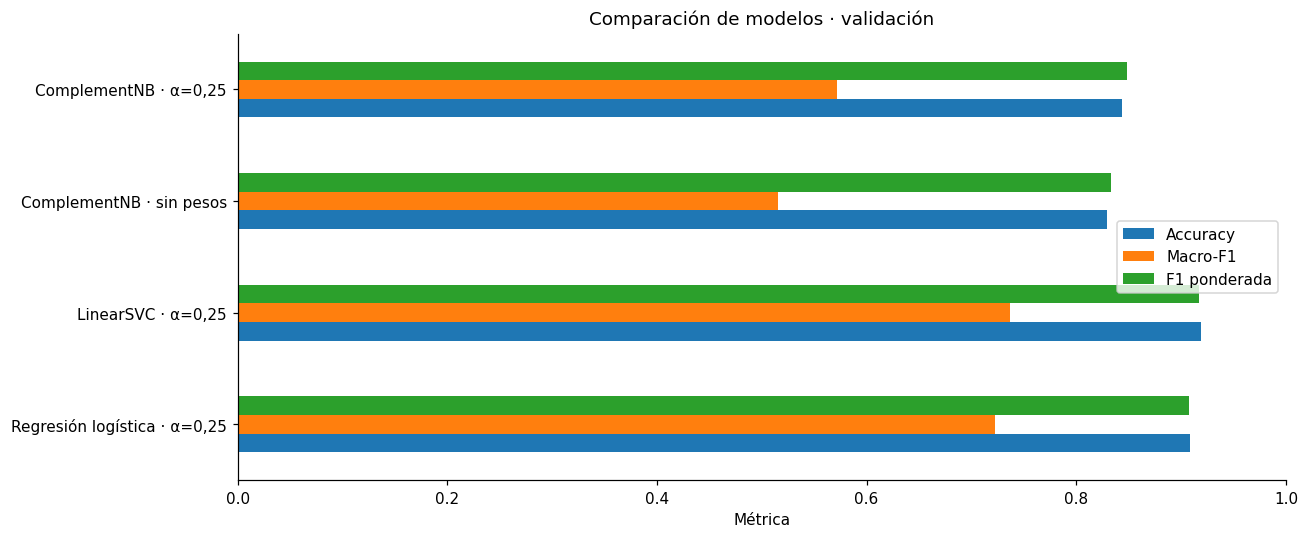

In [8]:
resumen = resumir_comparacion(comparacion)
display(resumen["metricas"].round(4))
display(resumen["cambios"].round(4))
display(resumen["tiempos"].round(2))
fig, ax = plt.subplots(figsize=(12,5))
resumen["metricas"].plot.barh(ax=ax)
ax.set(title="Comparación de modelos · validación", xlabel="Métrica", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()

## 9. Rendimiento por categoría

,"Regresión logística · α=0,25","LinearSVC · α=0,25",ComplementNB · sin pesos,"ComplementNB · α=0,25"
Checking or savings account,0.8144,0.8104,0.5816,0.6151
Credit card,0.7939,0.7961,0.6454,0.6768
Credit reporting or other personal consumer reports,0.9585,0.9663,0.9205,0.9271
Debt collection,0.7608,0.8002,0.6723,0.6788
Debt or credit management,0.2111,0.2752,0.0116,0.0223
"Money transfer, virtual currency, or money service",0.6957,0.6774,0.2771,0.4355
Mortgage,0.8837,0.8917,0.7949,0.7792
"Payday loan, title loan, personal loan, or advance loan",0.5529,0.5591,0.0643,0.2075
Prepaid card,0.7274,0.7416,0.4732,0.6251
Student loan,0.8834,0.9035,0.7613,0.7637


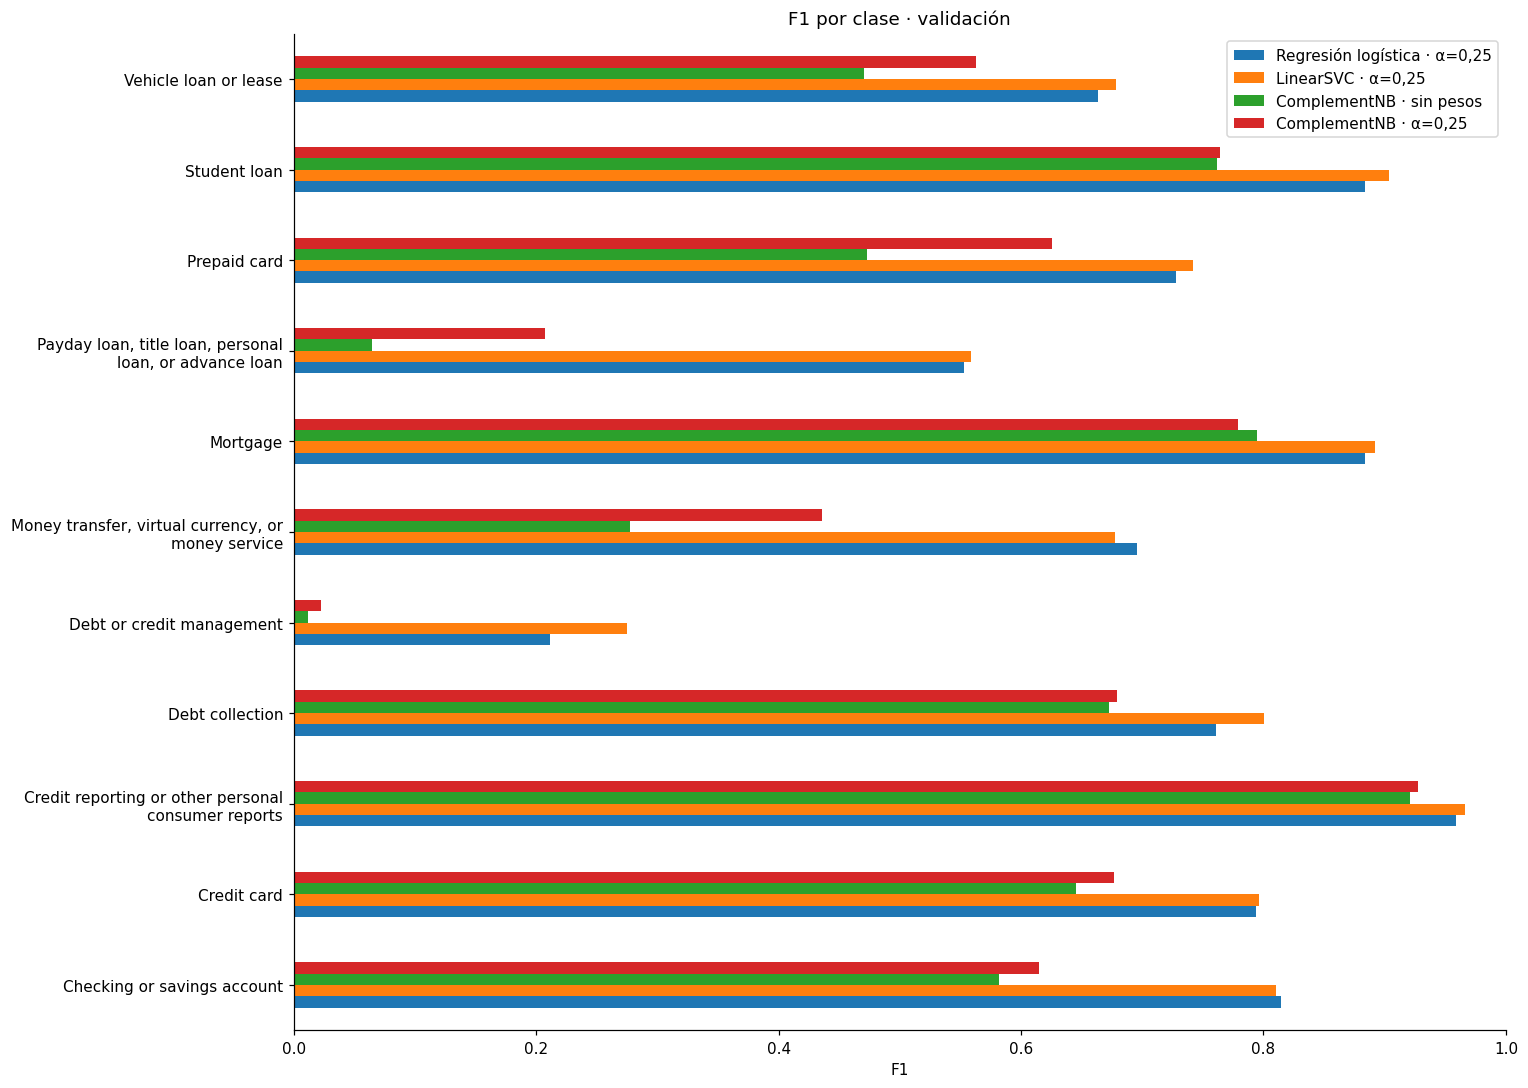

precision  \
Modelo                       Product                                                         
Regresión logística · α=0,25 Checking or savings account                            0.7783   
                             Credit card                                            0.7834   
                             Credit reporting or other personal consumer rep...     0.9598   
                             Debt collection                                        0.7616   
                             Debt or credit management                              0.7778   
                             Money transfer, virtual currency, or money service     0.7276   
                             Mortgage                                               0.8675   
                             Payday loan, title loan, personal loan, or adva...     0.5941   
                             Prepaid card                                           0.7812   
                             Student loan                                           0.8923   
                             Vehicle loan or lease                                  0.6609   
LinearSVC · α=0,25           Checking or savings account                            0.7866   
                             Credit card                                            0.7963   
                             Credit reporting or other personal consumer rep...     0.9612   
                             Debt collection                                        0.8174   
                             Debt or credit management                              0.6522   
                             Money transfer, virtual currency, or money service     0.7053   
                             Mortgage                                               0.8921   
                             Payday loan, title loan, personal loan, or adva...     0.6209   
                             Prepaid card                                           0.8394   
                             Student loan                                           0.9228   
                             Vehicle loan or lease                                  0.7090   
ComplementNB · sin pesos     Checking or savings account                            0.4187   
                             Credit card                                            0.5577   
                             Credit reporting or other personal consumer rep...     0.9647   
                             Debt collection                                        0.6572   
                             Debt or credit management                              1.0000   
                             Money transfer, virtual currency, or money service     0.8364   
                             Mortgage                                               0.7506   
                             Payday loan, title loan, personal loan, or adva...     0.5333   
                             Prepaid card                                           0.9773   
                             Student loan                                           0.7119   
                             Vehicle loan or lease                                  0.5531   
ComplementNB · α=0,25        Checking or savings account                            0.4539   
                             Credit card                                            0.6309   
                             Credit reporting or other personal consumer rep...     0.9633   
                             Debt collection                                        0.6907   
                             Debt or credit management                              0.2857   
                             Money transfer, virtual currency, or money service     0.8020   
                             Mortgage                                               0.6767   
                             Payday loan, title loan, personal loan, or adva...     0.6027   
                             Prepaid ca

In [9]:
display(resumen["f1_clases"].round(4))
f1_plot = resumen["f1_clases"].copy()
f1_plot.index = [fill(label,38) for label in f1_plot.index]
fig, ax = plt.subplots(figsize=(14,10))
f1_plot.plot.barh(ax=ax)
ax.set(title="F1 por clase · validación", xlabel="F1", ylabel="", xlim=(0,1))
plt.tight_layout(); plt.show()
reportes = pd.concat({name: r["reporte"] for name, r in comparacion["resultados"].items()},
                     names=["Modelo", "Product"])
with pd.option_context("display.max_rows",100):
    display(reportes.round(4))

## 10. Empresas y textos vistos en entrenamiento

In [10]:
with pd.option_context("display.max_rows",100):
    display(resumen["empresas"].round(4))
    display(resumen["textos"].round(4))

Filas  \
Modelo                       Grupo                                           
Regresión logística · α=0,25 TRANSUNION INTERMEDIATE HOLDINGS, INC.  20842   
                             EQUIFAX, INC.                           20305   
                             Experian Information Solutions Inc.     19599   
                             Resto de empresas                       26628   
LinearSVC · α=0,25           TRANSUNION INTERMEDIATE HOLDINGS, INC.  20842   
                             EQUIFAX, INC.                           20305   
                             Experian Information Solutions Inc.     19599   
                             Resto de empresas                       26628   
ComplementNB · sin pesos     TRANSUNION INTERMEDIATE HOLDINGS, INC.  20842   
                             EQUIFAX, INC.                           20305   
                             Experian Information Solutions Inc.     19599   
                             Resto de empresas                       26628   
ComplementNB · α=0,25        TRANSUNION INTERMEDIATE HOLDINGS, INC.  20842   
                             EQUIFAX, INC.                           20305   
                             Experian Information Solutions Inc.     19599   
                             Resto de empresas                       26628   

                                                                     Clases presentes  \
Modelo                       Grupo                                                      
Regresión logística · α=0,25 TRANSUNION INTERMEDIATE HOLDINGS, INC.                 8   
                             EQUIFAX, INC.                                          8   
                             Experian Information Solutions Inc.                    7   
                             Resto de empresas                                     11   
LinearSVC · α=0,25           TRANSUNION INTERMEDIATE HOLDINGS, INC.                 8   
                             EQUIFAX, INC.                                          8   
                             Experian Information Solutions Inc.                    7   
                             Resto de empresas                                     11   
ComplementNB · sin pesos     TRANSUNION INTERMEDIATE HOLDINGS, INC.                 8   
                             EQUIFAX, INC.                                          8   
                             Experian Information Solutions Inc.                    7   
                             Resto de empresas                                     11   
ComplementNB · α=0,25        TRANSUNION INTERMEDIATE HOLDINGS, INC.                 8   
                             EQUIFAX, INC.                                          8   
                             Experian Information Solutions Inc.                    7   
                             Resto de empresas                                     11   

                                                                     Accuracy  \
Modelo                       Grupo                                              
Regresión logística · α=0,25 TRANSUNION INTERMEDIATE HOLDINGS, INC.    0.9633   
                             EQUIFAX, INC.                             0.9676   
                             Experian Information Solutions Inc.       0.9632   
                             Resto de empresas                         0.7792   
LinearSVC · α=0,25           TRANSUNION INTERMEDIATE HOLDINGS, INC.    0.9743   
                             EQUIFAX, INC.                             0.9790   
                             Experian Information Solutions Inc.       0.9745   
                             Resto de empresas                         0.7875   
ComplementNB · sin pesos     TRANSUNION INTERMEDIATE HOLDINGS, INC.    0.9051   
                             EQUIFAX, INC.                             0.9091   
                             Experian Information Solutions Inc.       0.8895   
        

Texto visto en entrenamiento  Filas  Accuracy  \
Modelo                                                                          
Regresión logística · α=0,25 0                          True  36779    0.9640   
                             1                         False  50595    0.8676   
LinearSVC · α=0,25           0                          True  36779    0.9759   
                             1                         False  50595    0.8768   
ComplementNB · sin pesos     0                          True  36779    0.9274   
                             1                         False  50595    0.7575   
ComplementNB · α=0,25        0                          True  36779    0.9331   
                             1                         False  50595    0.7786   

                                Macro-F1  F1 ponderada  
Modelo                                                  
Regresión logística · α=0,25 0    0.4626        0.9655  
                             1    0.7209        0.8660  
LinearSVC · α=0,25           0    0.5844        0.9761  
                             1    0.7311        0.8744  
ComplementNB · sin pesos     0    0.3615        0.9375  
                             1    0.5141        0.7589  
ComplementNB · α=0,25        0    0.4051        0.9424  
                             1    0.5721        0.7805

## 11. Matrices de confusión y errores más frecuentes

,Matriz de confusión
Modelo,"Regresión logística · α=0,25"


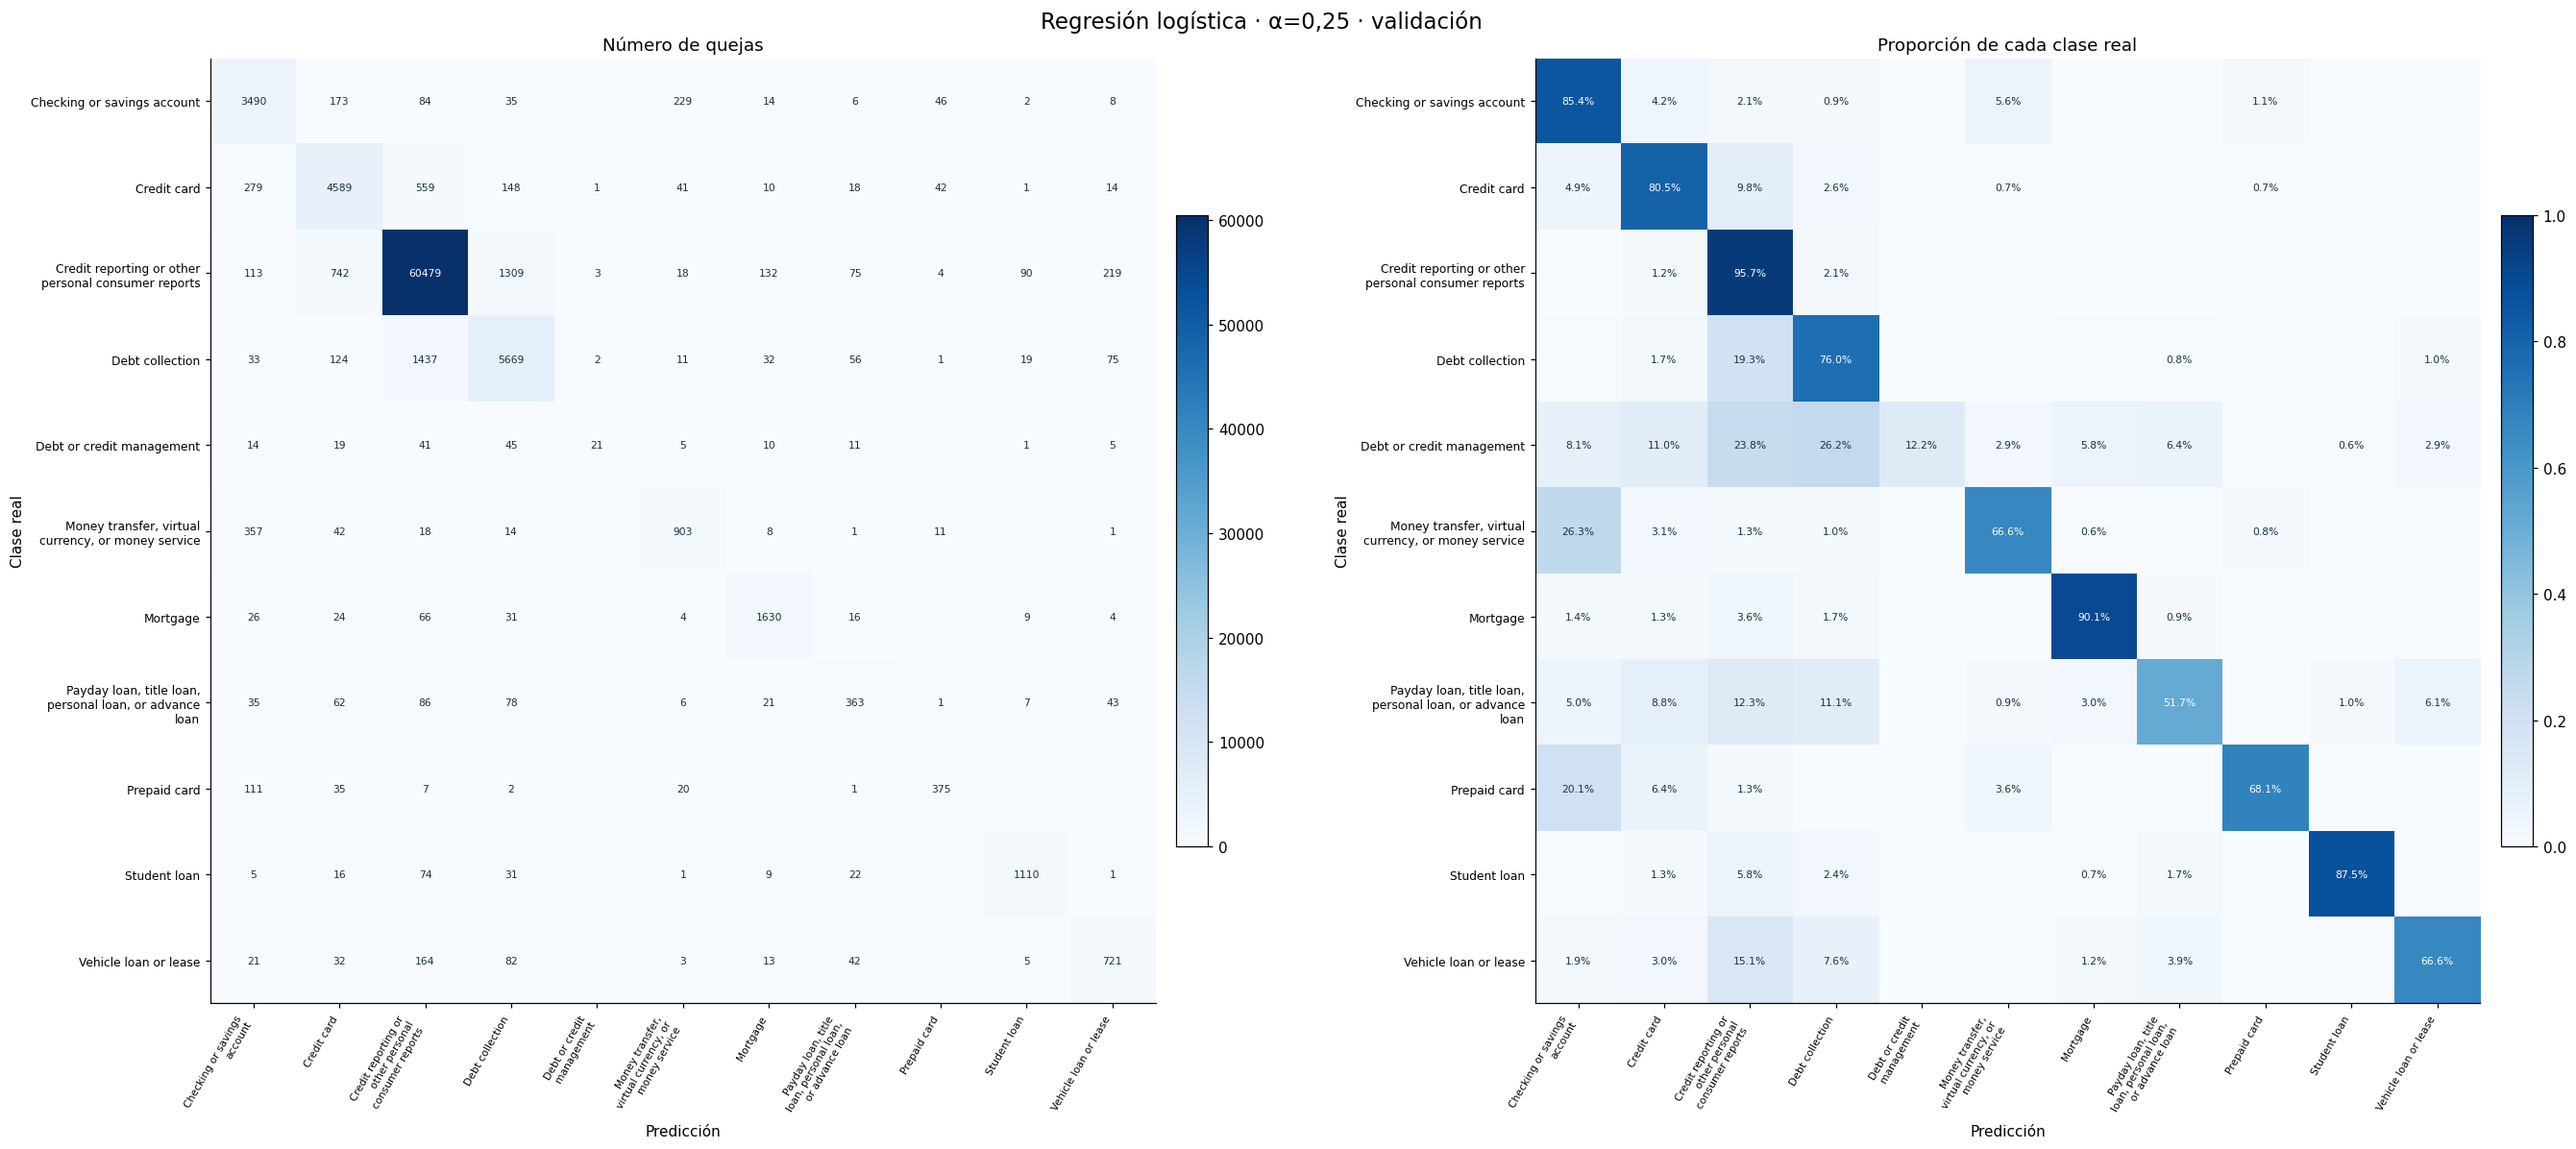

,Matriz de confusión
Modelo,"LinearSVC · α=0,25"


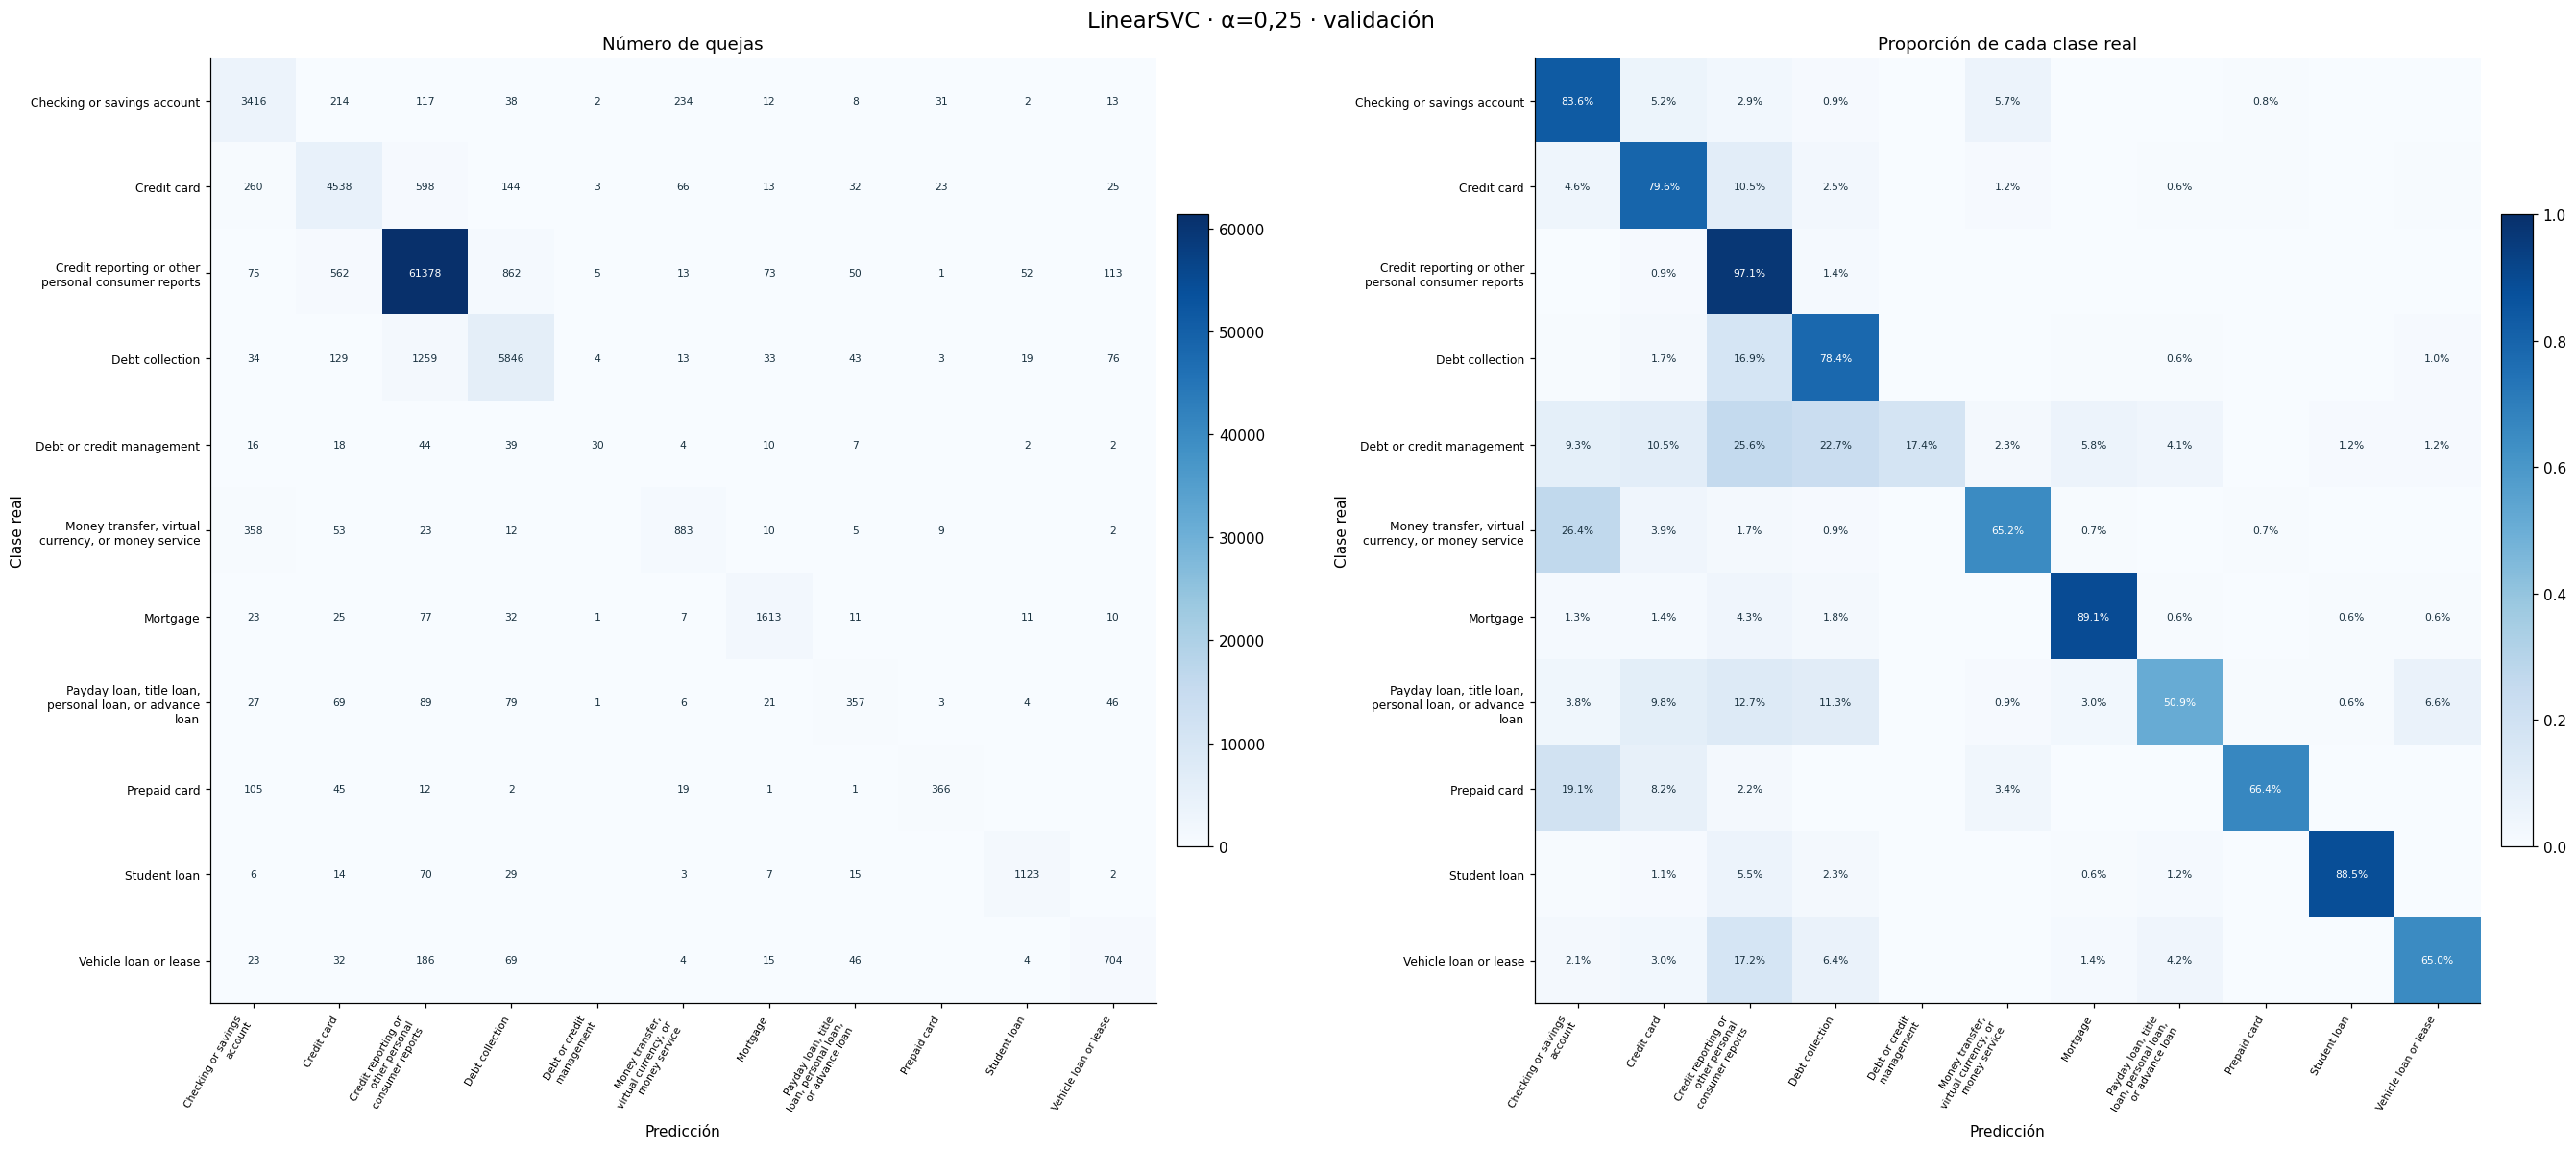

,Errores más frecuentes
Modelo,"Regresión logística · α=0,25"


,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Debt collection,Credit reporting or other personal consumer re...,1437,19.27,17.91
1,Credit reporting or other personal consumer re...,Debt collection,1309,2.07,16.31
2,Credit reporting or other personal consumer re...,Credit card,742,1.17,9.25
3,Credit card,Credit reporting or other personal consumer re...,559,9.80,6.97
4,"Money transfer, virtual currency, or money ser...",Checking or savings account,357,26.35,4.45
5,Credit card,Checking or savings account,279,4.89,3.48
6,Checking or savings account,"Money transfer, virtual currency, or money ser...",229,5.60,2.85
7,Credit reporting or other personal consumer re...,Vehicle loan or lease,219,0.35,2.73
8,Checking or savings account,Credit card,173,4.23,2.16
9,Vehicle loan or lease,Credit reporting or other personal consumer re...,164,15.14,2.04


,Errores más frecuentes
Modelo,"LinearSVC · α=0,25"


,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Debt collection,Credit reporting or other personal consumer re...,1259,16.88,17.68
1,Credit reporting or other personal consumer re...,Debt collection,862,1.36,12.11
2,Credit card,Credit reporting or other personal consumer re...,598,10.49,8.40
3,Credit reporting or other personal consumer re...,Credit card,562,0.89,7.89
4,"Money transfer, virtual currency, or money ser...",Checking or savings account,358,26.42,5.03
5,Credit card,Checking or savings account,260,4.56,3.65
6,Checking or savings account,"Money transfer, virtual currency, or money ser...",234,5.73,3.29
7,Checking or savings account,Credit card,214,5.24,3.01
8,Vehicle loan or lease,Credit reporting or other personal consumer re...,186,17.17,2.61
9,Credit card,Debt collection,144,2.53,2.02


,Errores más frecuentes
Modelo,ComplementNB · sin pesos


,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Credit reporting or other personal consumer re...,Credit card,2396,3.79,16.04
1,Credit reporting or other personal consumer re...,Debt collection,2263,3.58,15.15
2,Credit reporting or other personal consumer re...,Checking or savings account,1857,2.94,12.43
3,Debt collection,Credit reporting or other personal consumer re...,1522,20.40,10.19
4,"Money transfer, virtual currency, or money ser...",Checking or savings account,1072,79.11,7.18
5,Credit card,Checking or savings account,913,16.01,6.11
6,Debt collection,Checking or savings account,409,5.48,2.74
7,Credit reporting or other personal consumer re...,Student loan,385,0.61,2.58
8,Credit reporting or other personal consumer re...,Mortgage,368,0.58,2.46
9,Credit card,Credit reporting or other personal consumer re...,287,5.03,1.92


,Errores más frecuentes
Modelo,"ComplementNB · α=0,25"


,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Credit reporting or other personal consumer re...,Debt collection,1907,3.02,13.96
1,Credit reporting or other personal consumer re...,Credit card,1879,2.97,13.75
2,Debt collection,Credit reporting or other personal consumer re...,1580,21.18,11.57
3,Credit reporting or other personal consumer re...,Checking or savings account,1474,2.33,10.79
4,Credit card,Checking or savings account,1032,18.10,7.55
5,"Money transfer, virtual currency, or money ser...",Checking or savings account,904,66.72,6.62
6,Credit reporting or other personal consumer re...,Student loan,486,0.77,3.56
7,Credit reporting or other personal consumer re...,Mortgage,483,0.76,3.54
8,Debt collection,Checking or savings account,438,5.87,3.21
9,Credit reporting or other personal consumer re...,Vehicle loan or lease,435,0.69,3.18


In [11]:
scores = resumen["metricas"]
mejor = scores["Macro-F1"].idxmax()
for nombre in dict.fromkeys([REFERENCE, mejor]):
    display(pd.Series({"Modelo":nombre},name="Matriz de confusión").to_frame())
    mostrar_matrices(comparacion,nombre)
for nombre in comparacion["resultados"]:
    display(pd.Series({"Modelo":nombre},name="Errores más frecuentes").to_frame())
    display(errores_frecuentes(comparacion,nombre).head(15).round(2))

## 12. Conclusiones y siguientes pruebas

In [12]:
display(pd.Series({
    "Referencia aprobada": REFERENCE,
    "Mayor macro-F1 observado": mejor,
    "Macro-F1": round(scores.loc[mejor,"Macro-F1"],4),
    "Diferencia frente a referencia": round(scores.loc[mejor,"Macro-F1"]-scores.loc[REFERENCE,"Macro-F1"],4),
    "Estado": "Comparación inicial; no adopta automáticamente un nuevo modelo",
    "Pendiente": "Ajustar hiperparámetros con presupuesto comparable y revisar estabilidad",
    "Confianza": "Las puntuaciones de los distintos modelos no son probabilidades calibradas comparables",
    "Prueba": "Reservada; no evaluada",
}, name="Conclusiones").to_frame())

,Conclusiones
Referencia aprobada,"Regresión logística · α=0,25"
Mayor macro-F1 observado,"LinearSVC · α=0,25"
Macro-F1,0.7363
Diferencia frente a referencia,0.0141
Estado,Comparación inicial; no adopta automáticamente...
Pendiente,Ajustar hiperparámetros con presupuesto compar...
Confianza,Las puntuaciones de los distintos modelos no s...
Prueba,Reservada; no evaluada


## 13. Piloto semántico en CPU: entorno y protocolo

In [1]:
from pathlib import Path
import gc, sys, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "cfpb_complaints_2023-06-01_2024-05-31").is_dir())
for folder in [ROOT / "Baseline", ROOT / "Modelado"]:
    if str(folder) not in sys.path: sys.path.insert(0,str(folder))
from baseline import cargar_datos, crear_particiones
from comparacion import (preparar_comparacion, catalogo_modelos, entrenar_modelo,
                         resumir_comparacion, mostrar_matrices, errores_frecuentes, REFERENCE)
from semanticos import seleccionar_piloto, entrenar_minilm, entrenar_distilbert, MINILM, DISTIL
import torch, transformers
# Liberar las matrices del corte completo antes de cargar el piloto.
for variable in ["datos", "comparacion", "modelos"]:
    globals().pop(variable,None)
gc.collect()
N_TRAIN_PILOTO = 11000
N_VALIDACION_PILOTO = 5500
MAX_TOKENS = 128
EPOCAS_DISTILBERT = 1
# Para una comparación completa posterior con GPU, utilizar None en ambos tamaños.
display(pd.Series({
    "Alcance": "Piloto exploratorio; comparar solo los modelos de esta sección entre sí",
    "Entrenamiento": N_TRAIN_PILOTO,
    "Validación": N_VALIDACION_PILOTO,
    "Muestreo": "Estratificado por producto dentro de las particiones fijadas; semilla 42",
    "Referencias": "Reentrenadas desde cero sobre las mismas filas del piloto",
    "MiniLM": "Encoder congelado, mean pooling y normalización L2; regresión logística α=0,25",
    "DistilBERT": "Ajuste de toda la red y cabeza de 11 clases; pérdida ponderada α=0,25",
    "Tokens máximos": MAX_TOKENS,
    "Textos largos": "Inicio [SEP] final; se recorta la parte central y se informa el porcentaje afectado",
    "Presupuesto DistilBERT": "Una época, lote 16, AdamW, learning rate 2e-5; sin búsqueda ni parada temprana",
    "Dispositivo": "cuda" if torch.cuda.is_available() else "cpu",
    "PyTorch": torch.__version__, "Transformers": transformers.__version__,
    "Prueba": "Sin evaluación",
    "Limitación": "Pocos casos de clases pequeñas y presupuesto reducido; no permite descartar una arquitectura",
}, name="Protocolo del piloto").to_frame())

/tmp/clasificador_neural_deps/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Protocolo del piloto
Alcance,Piloto exploratorio; comparar solo los modelos...
Entrenamiento,11000
Validación,5500
Muestreo,Estratificado por producto dentro de las parti...
Referencias,Reentrenadas desde cero sobre las mismas filas...
MiniLM,"Encoder congelado, mean pooling y normalizació..."
DistilBERT,Ajuste de toda la red y cabeza de 11 clases; p...
Tokens máximos,128
Textos largos,Inicio [SEP] final; se recorta la parte centra...
Presupuesto DistilBERT,"Una época, lote 16, AdamW, learning rate 2e-5;..."


## 14. Muestra, soporte e identificadores del piloto

In [2]:
datos_piloto = cargar_datos(ROOT)
particiones_originales = crear_particiones(datos_piloto)
particiones_piloto = seleccionar_piloto(datos_piloto,particiones_originales,
    n_train=N_TRAIN_PILOTO,n_validation=N_VALIDACION_PILOTO)
soporte_piloto = pd.DataFrame({name:datos_piloto.iloc[ids].Product.value_counts()
                             for name,ids in particiones_piloto.items()}).fillna(0).astype(int)
display(soporte_piloto)
display(pd.Series({name:hashlib.sha256("\n".join(sorted(datos_piloto.iloc[ids]["Complaint ID"])).encode()).hexdigest()
                   for name,ids in particiones_piloto.items()},name="SHA-256 de IDs").to_frame())
piloto = preparar_comparacion(datos_piloto,particiones_piloto)
modelos_piloto = catalogo_modelos(piloto)
display(piloto["pesos"].to_frame())

,Entrenamiento,Validación
Product,,
Credit reporting or other personal consumer reports,7955,3977
Debt collection,939,470
Credit card,718,359
Checking or savings account,514,257
Mortgage,228,114
"Money transfer, virtual currency, or money service",171,85
Student loan,160,80
Vehicle loan or lease,136,68
"Payday loan, title loan, personal loan, or advance loan",88,44


,SHA-256 de IDs
Entrenamiento,379d7ff446c5dab32a1dce55143f829826272a5b3f79d3...
Validación,17ba34201e02ca2c838661aa5651d692ea75adb470b8e9...


,Peso
Checking or savings account,1.527701
Credit card,1.405232
Credit reporting or other personal consumer reports,0.770228
Debt collection,1.314053
Debt or credit management,3.358718
"Money transfer, virtual currency, or money service",2.011547
Mortgage,1.871955
"Payday loan, title loan, personal loan, or advance loan",2.374972
Prepaid card,2.523869
Student loan,2.045263


## 15. Referencias clásicas reentrenadas sobre el piloto

In [3]:
for nombre,(modelo,ponderar_filas) in modelos_piloto.items():
    display(entrenar_modelo(piloto,nombre,modelo,ponderar_filas))

,"Regresión logística · α=0,25"
Accuracy,0.873455
Macro-F1,0.568513
F1 ponderada,0.862574
Ajuste (s),7.481107
Predicción validación (s),0.029877
Iteraciones,44
Avisos,Sin avisos


,"LinearSVC · α=0,25"
Accuracy,0.881818
Macro-F1,0.619784
F1 ponderada,0.875467
Ajuste (s),1.661979
Predicción validación (s),0.015686
Iteraciones,65
Avisos,Sin avisos


,ComplementNB · sin pesos
Accuracy,0.838909
Macro-F1,0.44968
F1 ponderada,0.821603
Ajuste (s),0.055174
Predicción validación (s),0.015768
Iteraciones,None
Avisos,Sin avisos


,"ComplementNB · α=0,25"
Accuracy,0.852182
Macro-F1,0.532204
F1 ponderada,0.843533
Ajuste (s),0.056747
Predicción validación (s),0.015743
Iteraciones,None
Avisos,Sin avisos


## 16. MiniLM congelado y regresión logística

In [4]:
display(entrenar_minilm(piloto,max_tokens=MAX_TOKENS,batch_size=32))
display(piloto["resultados"][MINILM]["recorte"].round(2))
display(pd.Series(piloto["resultados"][MINILM]["costes_neuronales"],name="Tiempos (s)").round(2).to_frame())
display(pd.Series(piloto["resultados"][MINILM]["configuracion"],name="Configuración").to_frame())

,"MiniLM + regresión logística · α=0,25"
Accuracy,0.860727
Macro-F1,0.616076
F1 ponderada,0.857526
Ajuste (s),0.661907
Predicción validación (s),0.01956
Iteraciones,36
Avisos,Sin avisos


,Filas,Con recorte,% con recorte,Tokens originales medios,Tokens originales p95,Máximo de entrada
Entrenamiento,11000,6057,55.06,230.10,700.05,128
Validación,5500,3047,55.40,229.52,691.05,128


,Tiempos (s)
Tokenización (s),9.09
Carga modelo (s),0.19
Codificación entrenamiento (s),266.45
Codificación validación (s),140.85
Ajuste clasificador (s),0.66
Predicción clasificador (s),0.02


,Configuración
C,1.0
class_weight,{'Checking or savings account': 1.527701055833...
dual,False
fit_intercept,True
intercept_scaling,1
l1_ratio,0.0
max_iter,300
n_jobs,None
penalty,deprecated
random_state,42


## 17. Ajuste supervisado de DistilBERT

In [5]:
display(entrenar_distilbert(piloto,max_tokens=MAX_TOKENS,batch_size=16,
                           epochs=EPOCAS_DISTILBERT,learning_rate=2e-5))
display(piloto["resultados"][DISTIL]["recorte"].round(2))
display(piloto["resultados"][DISTIL]["historia"].round(4))
display(pd.Series(piloto["resultados"][DISTIL]["costes_neuronales"],name="Tiempos (s)").round(2).to_frame())
display(pd.Series(piloto["resultados"][DISTIL]["configuracion"],name="Configuración").to_frame())

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


DistilBERT época 1: 100/688 lotes


DistilBERT época 1: 200/688 lotes


DistilBERT época 1: 300/688 lotes


DistilBERT época 1: 400/688 lotes


...

,"DistilBERT ajustado · α=0,25"
Accuracy,0.847636
Macro-F1,0.430199
F1 ponderada,0.83555
Ajuste (s),3212.884239
Predicción validación (s),452.306549
Iteraciones,None
Avisos,Sin avisos


,Filas,Con recorte,% con recorte,Tokens originales medios,Tokens originales p95,Máximo de entrada
Entrenamiento,11000,6057,55.06,230.10,700.05,128
Validación,5500,3047,55.40,229.52,691.05,128


,Época,Filas,Pérdida ponderada
0,1,11000,1.0641


,Tiempos (s)
Tokenización (s),10.08
Carga modelo (s),0.06
Ajuste red (s),3212.88
Predicción validación (s),452.31


,Configuración
Modelo base,distilbert/distilbert-base-uncased
Revisión,12040accade4e8a0f71eabdb258fecc2e7e948be
Tokens máximos,128
Lote,16
Épocas,1
Learning rate,0.00002
Dispositivo,cpu
Encoder ajustado,True
Peso de clase,"α=0,25, media 1"
Pérdida,Media por lote de entropía cruzada multiplicad...


## 18. Comparación del piloto: métricas y costes

,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
"Regresión logística · α=0,25",0.8735,0.5685,0.8626
"LinearSVC · α=0,25",0.8818,0.6198,0.8755
ComplementNB · sin pesos,0.8389,0.4497,0.8216
"ComplementNB · α=0,25",0.8522,0.5322,0.8435
"MiniLM + regresión logística · α=0,25",0.8607,0.6161,0.8575
"DistilBERT ajustado · α=0,25",0.8476,0.4302,0.8356


,Accuracy,Macro-F1,F1 ponderada
Modelo,,,
"Regresión logística · α=0,25",0.0000,0.0000,0.0000
"LinearSVC · α=0,25",0.0084,0.0513,0.0129
ComplementNB · sin pesos,-0.0345,-0.1188,-0.0410
"ComplementNB · α=0,25",-0.0213,-0.0363,-0.0190
"MiniLM + regresión logística · α=0,25",-0.0127,0.0476,-0.0050
"DistilBERT ajustado · α=0,25",-0.0258,-0.1383,-0.0270


,Ajuste (s),Predicción validación (s),Iteraciones,Avisos
"Regresión logística · α=0,25",7.481107,0.029877,44,Sin avisos
"LinearSVC · α=0,25",1.661979,0.015686,65,Sin avisos
ComplementNB · sin pesos,0.055174,0.015768,None,Sin avisos
"ComplementNB · α=0,25",0.056747,0.015743,None,Sin avisos
"MiniLM + regresión logística · α=0,25",0.661907,0.01956,36,Sin avisos
"DistilBERT ajustado · α=0,25",3212.884239,452.306549,None,Sin avisos


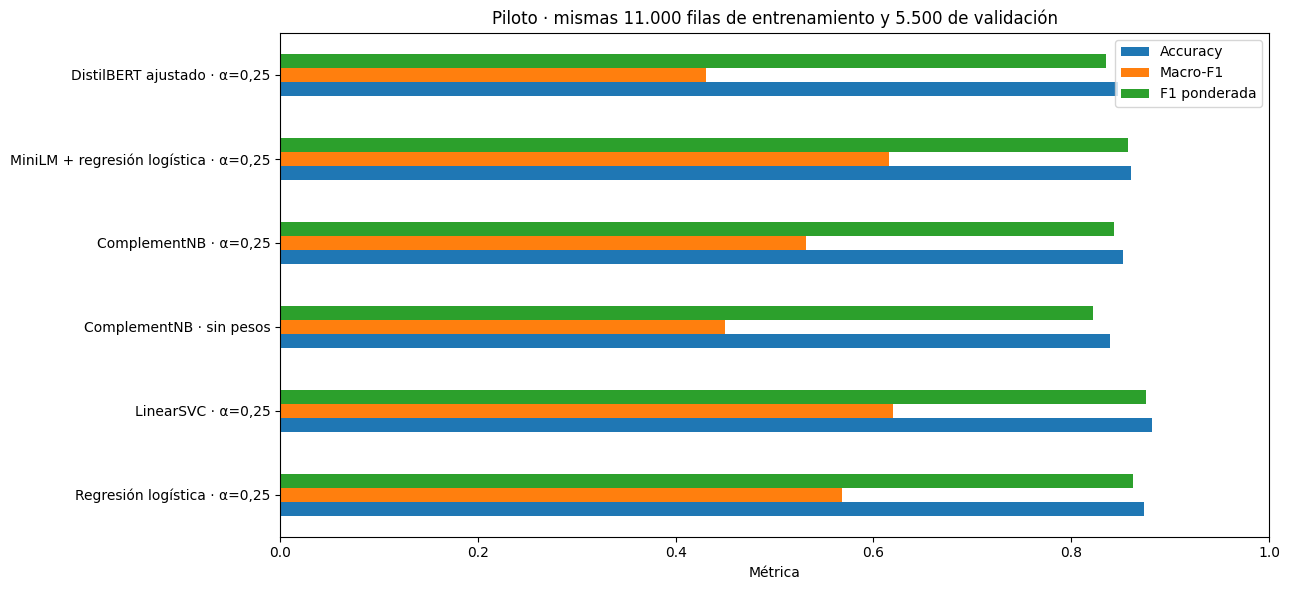

,Límites de interpretación
Lectura de tiempos,Ajuste excluye TF-IDF o codificación; consulta...
Comparabilidad,Estas cifras no se mezclan con las del corte c...
Modelos neuronales,128 tokens e inicio/final; los clásicos usan l...


In [6]:
resumen_piloto = resumir_comparacion(piloto)
display(resumen_piloto["metricas"].round(4))
display(resumen_piloto["cambios"].round(4))
display(resumen_piloto["tiempos"].round(2))
fig,ax=plt.subplots(figsize=(13,6))
resumen_piloto["metricas"].plot.barh(ax=ax)
ax.set(title="Piloto · mismas 11.000 filas de entrenamiento y 5.500 de validación",
       xlabel="Métrica",ylabel="",xlim=(0,1))
plt.tight_layout();plt.show()
display(pd.Series({
    "Lectura de tiempos": "Ajuste excluye TF-IDF o codificación; consultar también los costes por etapa",
    "Comparabilidad": "Estas cifras no se mezclan con las del corte completo",
    "Modelos neuronales": "128 tokens e inicio/final; los clásicos usan la narrativa completa",
},name="Límites de interpretación").to_frame())

## 19. Piloto: categorías, empresas y textos compartidos

In [7]:
display(resumen_piloto["f1_clases"].round(4))
with pd.option_context("display.max_rows",100):
    display(resumen_piloto["empresas"].round(4))
    display(resumen_piloto["textos"].round(4))
    display(pd.concat({name:r["reporte"] for name,r in piloto["resultados"].items()},
                      names=["Modelo","Product"]).round(4))

,"Regresión logística · α=0,25","LinearSVC · α=0,25",ComplementNB · sin pesos,"ComplementNB · α=0,25","MiniLM + regresión logística · α=0,25","DistilBERT ajustado · α=0,25"
Checking or savings account,0.7539,0.7483,0.6146,0.6303,0.7148,0.6990
Credit card,0.7059,0.7143,0.5960,0.6504,0.6964,0.6709
Credit reporting or other personal consumer reports,0.9390,0.9466,0.9337,0.9376,0.9356,0.9387
Debt collection,0.6683,0.6815,0.5254,0.5976,0.5991,0.5938
Debt or credit management,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"Money transfer, virtual currency, or money service",0.3717,0.4545,0.0674,0.2574,0.5270,0.0000
Mortgage,0.8224,0.8304,0.7184,0.7805,0.7436,0.6696
"Payday loan, title loan, personal loan, or advance loan",0.1633,0.2812,0.0851,0.0816,0.5333,0.0000
Prepaid card,0.5417,0.6545,0.2927,0.6275,0.6154,0.0000
Student loan,0.7826,0.8571,0.7761,0.8428,0.7975,0.6131


Filas  \
Modelo                                Grupo                                           
Regresión logística · α=0,25          EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   
LinearSVC · α=0,25                    EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   
ComplementNB · sin pesos              EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   
ComplementNB · α=0,25                 EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   
MiniLM + regresión logística · α=0,25 EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   
DistilBERT ajustado · α=0,25          EQUIFAX, INC.                            1326   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.   1268   
                                      Experian Information Solutions Inc.      1211   
                                      Resto de empresas                        1695   

                                                                              Clases presentes  \
Modelo                                Grupo                                                      
Regresión logística · α=0,25          EQUIFAX, INC.                                          4   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.                 6   
                                      Experian Information Solutions Inc.                    4   
                                      Resto de empresas                                     11   
LinearSVC · α=0,25                    EQUIFAX, INC.                                          4   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.                 6   
                                      Experian Information Solutions Inc.                    4   
                                      Resto de empresas                                     11   
ComplementNB · sin pesos              EQUIFAX, INC.                                          4   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.                 6   
                                      Experian Information Solutions Inc.                    4   
                                      Resto de empresas                                     11   
ComplementNB · α=0,25                 EQUIFAX, INC.                                          4   
                                      TRANSUNION INTERMEDIATE HOLDINGS, INC.                 6   
                                      Experian Information Solutions Inc.                    4   
                                      Resto de empresas                                     11   
MiniLM + regresión logística · α=0,25 EQUIFAX, INC.

Texto visto en entrenamiento  Filas  \
Modelo                                                                         
Regresión logística · α=0,25          0                          True   1164   
                                      1                         False   4336   
LinearSVC · α=0,25                    0                          True   1164   
                                      1                         False   4336   
ComplementNB · sin pesos              0                          True   1164   
                                      1                         False   4336   
ComplementNB · α=0,25                 0                          True   1164   
                                      1                         False   4336   
MiniLM + regresión logística · α=0,25 0                          True   1164   
                                      1                         False   4336   
DistilBERT ajustado · α=0,25          0                          True   1164   
                                      1                         False   4336   

                                         Accuracy  Macro-F1  F1 ponderada  
Modelo                                                                     
Regresión logística · α=0,25          0    0.9596    0.2347        0.9612  
                                      1    0.8503    0.5632        0.8360  
LinearSVC · α=0,25                    0    0.9622    0.2341        0.9625  
                                      1    0.8602    0.6153        0.8520  
ComplementNB · sin pesos              0    0.9416    0.2052        0.9376  
                                      1    0.8113    0.4452        0.7899  
ComplementNB · α=0,25                 0    0.9519    0.2247        0.9522  
                                      1    0.8254    0.5265        0.8137  
MiniLM + regresión logística · α=0,25 0    0.9510    0.2236        0.9502  
                                      1    0.8365    0.6120        0.8328  
DistilBERT ajustado · α=0,25          0    0.9510    0.2263        0.9519  
                                      1    0.8199    0.4252        0.8043

precision  \
Modelo                                Product                                                         
Regresión logística · α=0,25          Checking or savings account                            0.6835   
                                      Credit card                                            0.6787   
                                      Credit reporting or other personal consumer rep...     0.9119   
                                      Debt collection                                        0.8030   
                                      Debt or credit management                              0.0000   
                                      Money transfer, virtual currency, or money service     0.7500   
                                      Mortgage                                               0.8800   
                                      Payday loan, title loan, personal loan, or adva...     0.8000   
                                      Prepaid card                                           1.0000   
                                      Student loan                                           0.9310   
                                      Vehicle loan or lease                                  0.7429   
LinearSVC · α=0,25                    Checking or savings account                            0.6794   
                                      Credit card                                            0.7183   
                                      Credit reporting or other personal consumer rep...     0.9284   
                                      Debt collection                                        0.7578   
                                      Debt or credit management                              0.0000   
                                      Money transfer, virtual currency, or money service     0.6383   
                                      Mortgage                                               0.8455   
                                      Payday loan, title loan, personal loan, or adva...     0.4500   
                                      Prepaid card                                           0.9000   
                                      Student loan                                           0.9403   
                                      Vehicle loan or lease                                  0.8043   
ComplementNB · sin pesos              Checking or savings account                            0.4701   
                                      Credit card                                            0.5751   
                                      Credit reporting or other personal consumer rep...     0.9059   
                                      Debt collection                                        0.8265   
                                      Debt or credit management                              0.0000   
                                      Money transfer, virtual currency, or money service     0.7500   
                                      Mortgage                                               0.8043   
                                      Payday loan, title loan, personal loan, or adva...     0.6667   
                                      Prepaid card                                           1.0000   
                                      Student loan                                           0.9630   
                                      Vehicle loan or lease                                  0.7143   
ComplementNB · α=0,25                 Checking or savings account                            0.4788   
                                      Credit card                                            0.6332   
                                      Credit reporting or other personal consumer rep...     0.9274   
                                      Debt collection                                        0.8132   
                                      Debt or credit management          

## 20. Piloto: matrices de confusión y errores frecuentes

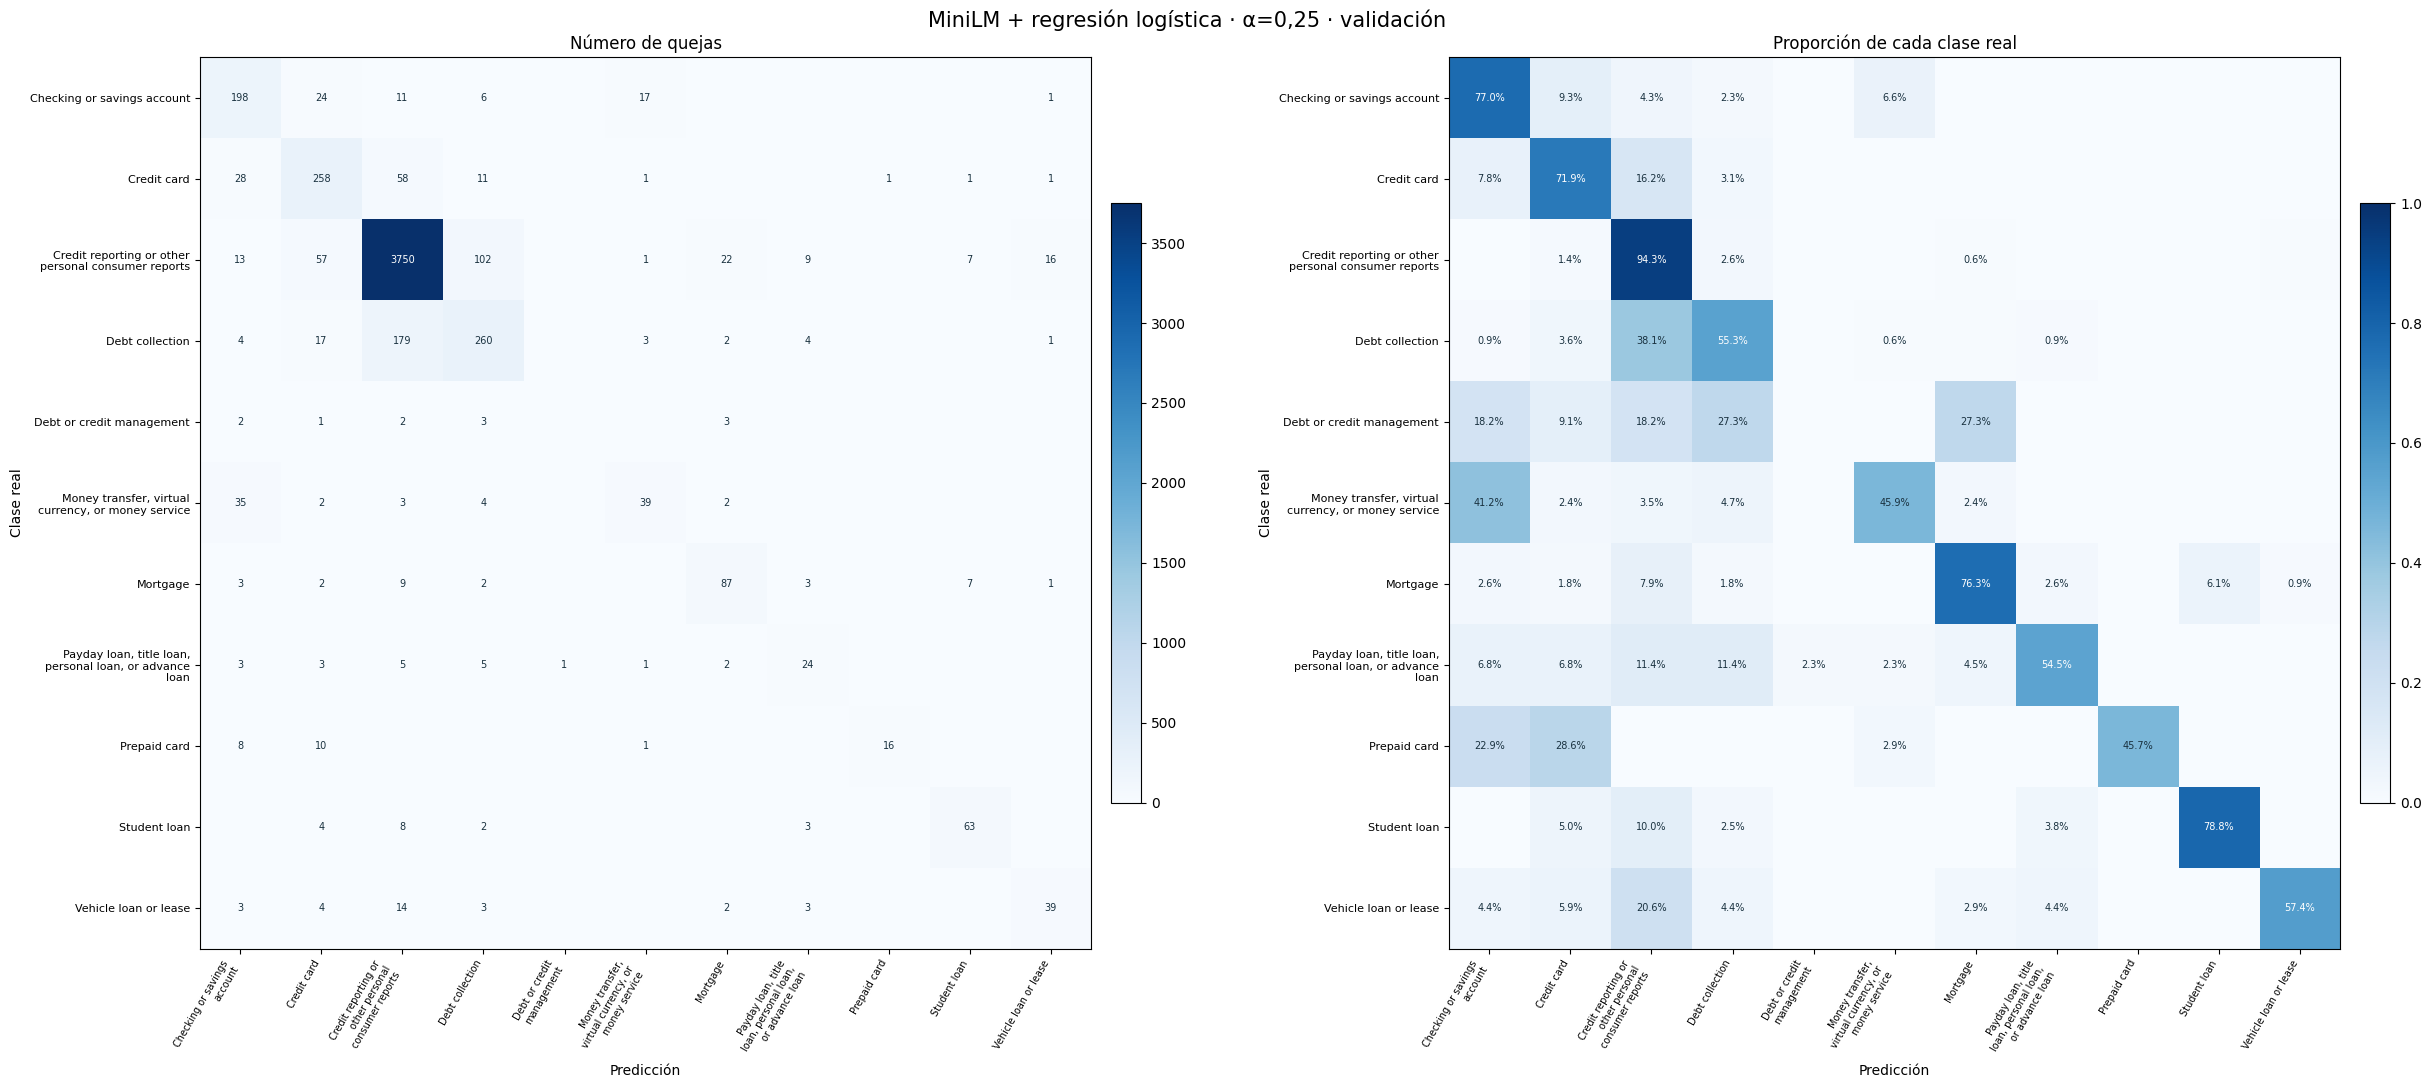

,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Debt collection,Credit reporting or other personal consumer re...,179,38.09,23.37
1,Credit reporting or other personal consumer re...,Debt collection,102,2.56,13.32
2,Credit card,Credit reporting or other personal consumer re...,58,16.16,7.57
3,Credit reporting or other personal consumer re...,Credit card,57,1.43,7.44
4,"Money transfer, virtual currency, or money ser...",Checking or savings account,35,41.18,4.57
5,Credit card,Checking or savings account,28,7.80,3.66
6,Checking or savings account,Credit card,24,9.34,3.13
7,Credit reporting or other personal consumer re...,Mortgage,22,0.55,2.87
8,Debt collection,Credit card,17,3.62,2.22
9,Checking or savings account,"Money transfer, virtual currency, or money ser...",17,6.61,2.22


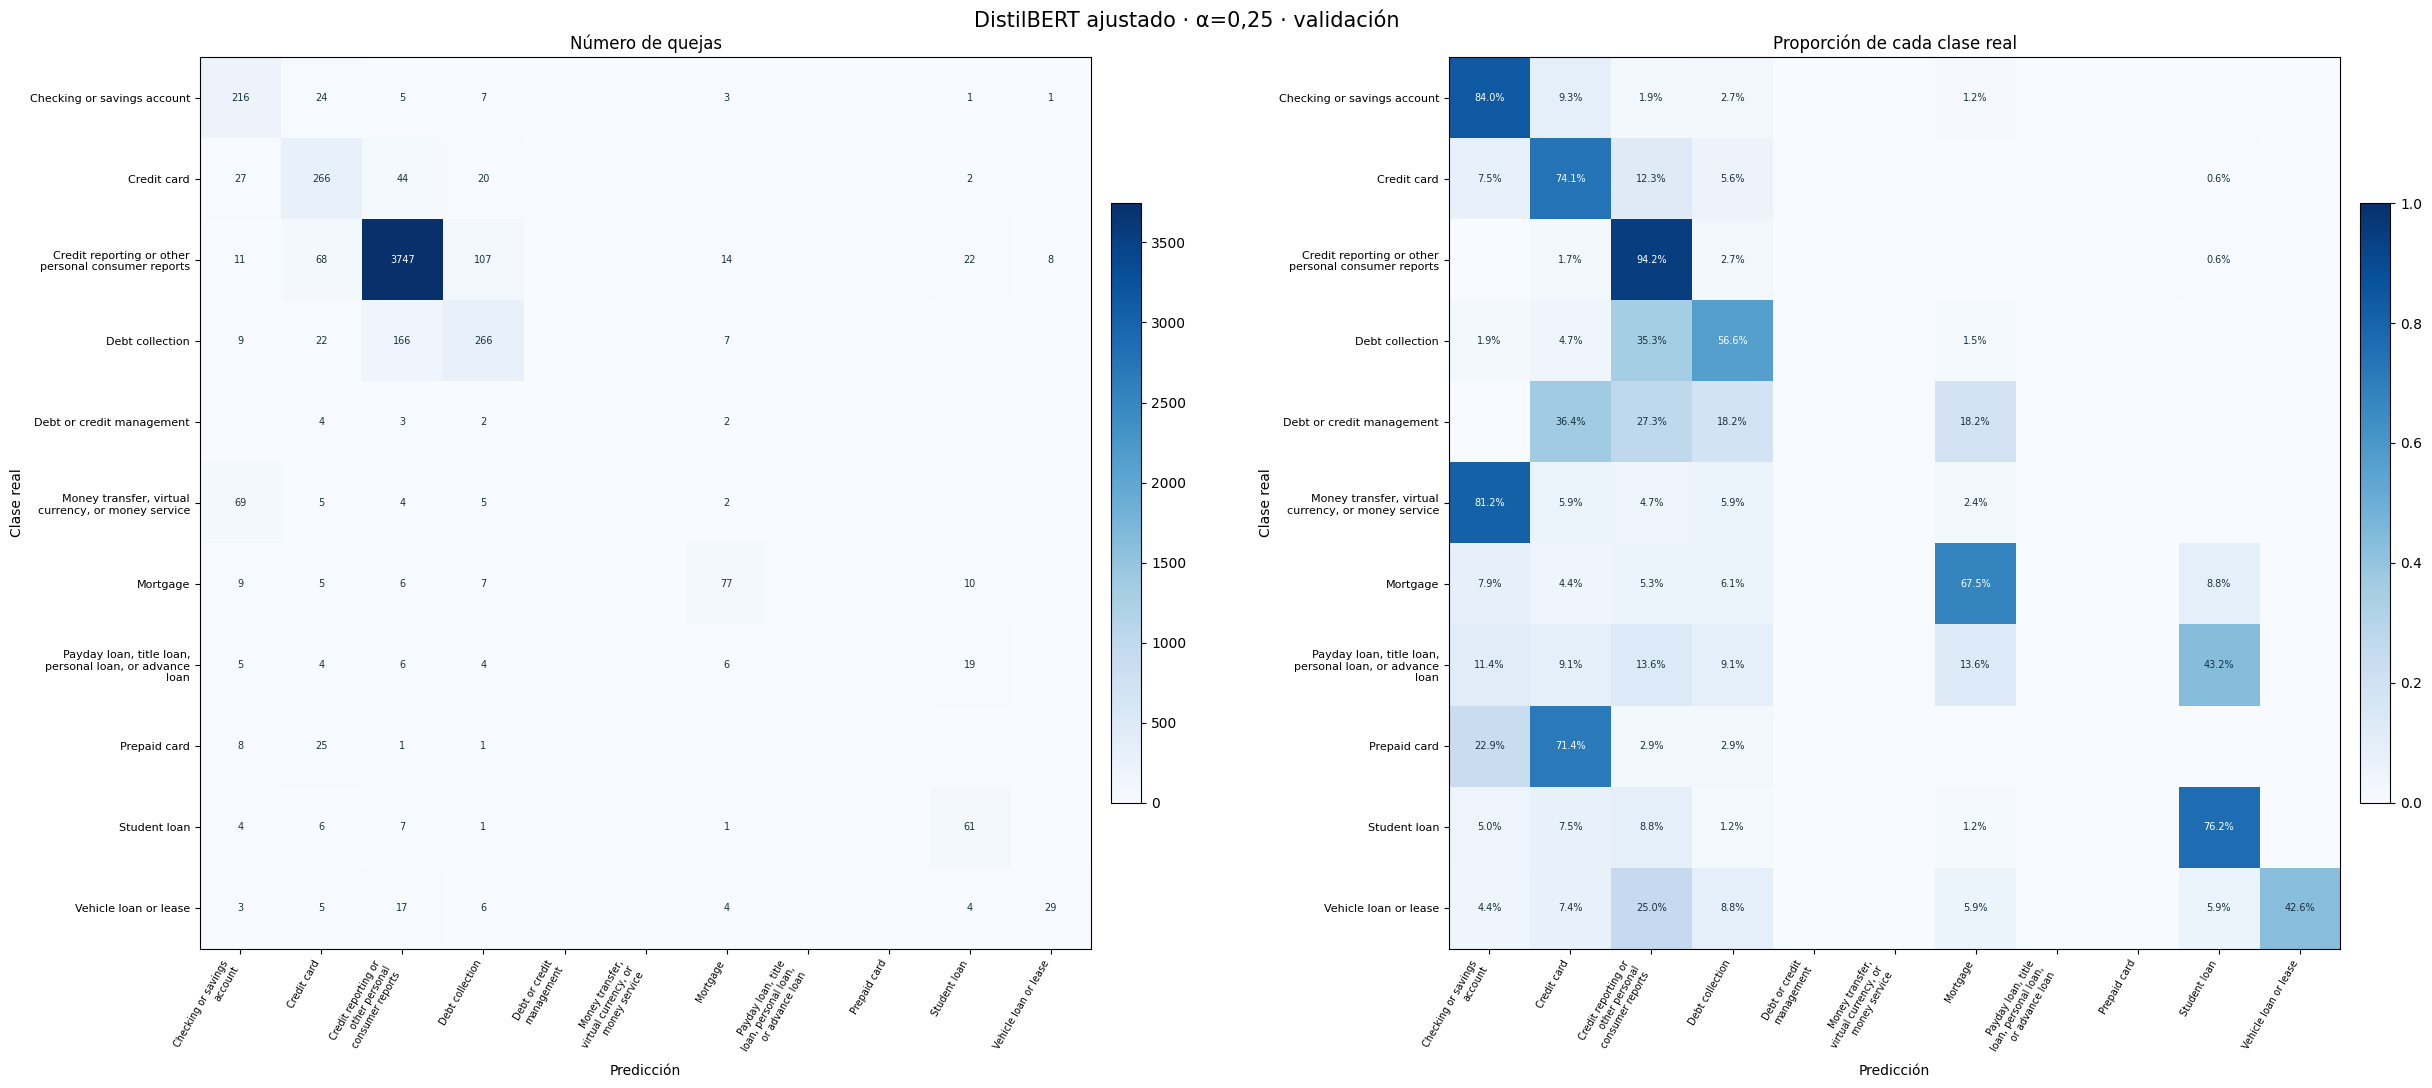

,Clase real,Predicción incorrecta,Errores,% de la clase real,% de todos los errores
0,Debt collection,Credit reporting or other personal consumer re...,166,35.32,19.81
1,Credit reporting or other personal consumer re...,Debt collection,107,2.69,12.77
2,"Money transfer, virtual currency, or money ser...",Checking or savings account,69,81.18,8.23
3,Credit reporting or other personal consumer re...,Credit card,68,1.71,8.11
4,Credit card,Credit reporting or other personal consumer re...,44,12.26,5.25
5,Credit card,Checking or savings account,27,7.52,3.22
6,Prepaid card,Credit card,25,71.43,2.98
7,Checking or savings account,Credit card,24,9.34,2.86
8,Debt collection,Credit card,22,4.68,2.63
9,Credit reporting or other personal consumer re...,Student loan,22,0.55,2.63


In [8]:
for nombre in [MINILM,DISTIL]:
    mostrar_matrices(piloto,nombre)
    display(errores_frecuentes(piloto,nombre).head(15).round(2))

## 21. Conclusiones del piloto y comparación completa pendiente

In [9]:
scores_piloto = resumen_piloto["metricas"]
mejor_piloto = scores_piloto["Macro-F1"].idxmax()
display(pd.Series({
    "Mejor macro-F1 del piloto": mejor_piloto,
    "Macro-F1": round(scores_piloto.loc[mejor_piloto,"Macro-F1"],4),
    "Referencia del piloto": round(scores_piloto.loc[REFERENCE,"Macro-F1"],4),
    "Validación": len(piloto["validation"]),
    "Estado": "Exploratorio; referencia aprobada sin cambios",
    "Limitaciones": "Muestra pequeña, textos recortados y una sola época de DistilBERT",
    "Próximo paso con GPU": "Mismas particiones completas, más contexto o fragmentación y presupuesto comparable de ajuste",
    "Prueba": "Reservada; no evaluada",
},name="Conclusiones del piloto").to_frame())
assert piloto["prueba_evaluada"] is False

,Conclusiones del piloto
Mejor macro-F1 del piloto,"LinearSVC · α=0,25"
Macro-F1,0.6198
Referencia del piloto,0.5685
Validación,5500
Estado,Exploratorio; referencia aprobada sin cambios
Limitaciones,"Muestra pequeña, textos recortados y una sola ..."
Próximo paso con GPU,"Mismas particiones completas, más contexto o f..."
Prueba,Reservada; no evaluada
